In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.models import load_model
from lime import lime_image
from skimage.segmentation import mark_boundaries

In [2]:
MODEL_PATH = "../Saved_Models/best_model_finetuned.keras"

model = load_model(MODEL_PATH)

print("Model je učitan.")
print("Broj slojeva:", len(model.layers))

Model je učitan.
Broj slojeva: 244


In [3]:
class_names = [
    "Mild_DR",
    "Moderate_DR",
    "No_DR",
    "Proliferate_DR",
    "Severe_DR"
]

IMG_SIZE = (224, 224)

In [4]:
def predict_images(images):
    images = np.asarray(images, dtype=np.float32)

    return model.predict(
        images,
        verbose=0
    )

In [8]:
IMAGE_PATH = (
    "../Dataset/"
    "Moderate_DR/"
    "000c1434d8d7.png"
)

img = tf.keras.utils.load_img(
    IMAGE_PATH,
    target_size=IMG_SIZE
)

img_array = tf.keras.utils.img_to_array(img)

print("Oblik slike:", img_array.shape)
print("Minimalna vrijednost:", img_array.min())
print("Maksimalna vrijednost:", img_array.max())

Oblik slike: (224, 224, 3)
Minimalna vrijednost: 0.0
Maksimalna vrijednost: 255.0


In [9]:
prediction = predict_images(
    np.expand_dims(img_array, axis=0)
)

predicted_index = int(
    np.argmax(prediction[0])
)

predicted_class = class_names[predicted_index]
confidence = float(
    prediction[0][predicted_index]
)

print("Predviđena klasa:", predicted_class)
print("Pouzdanost:", confidence)

for class_name, probability in zip(
    class_names,
    prediction[0]
):
    print(
        f"{class_name:16s}: "
        f"{probability:.4f}"
    )

Predviđena klasa: Moderate_DR
Pouzdanost: 0.4657779633998871
Mild_DR         : 0.2983
Moderate_DR     : 0.4658
No_DR           : 0.0089
Proliferate_DR  : 0.2158
Severe_DR       : 0.0113


In [10]:
explainer = lime_image.LimeImageExplainer(
    random_state=42
)

explanation = explainer.explain_instance(
    image=img_array.astype(np.double),
    classifier_fn=predict_images,
    top_labels=5,
    hide_color=0,
    num_samples=1000
)

print("LIME objašnjenje je generirano.")

  0%|          | 0/1000 [00:00<?, ?it/s]

LIME objašnjenje je generirano.


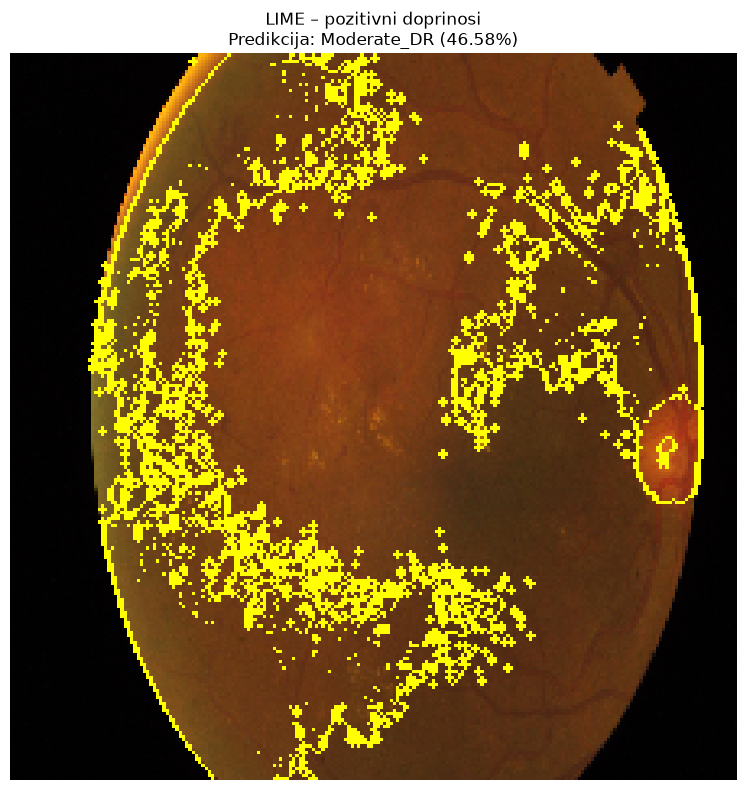

In [11]:
lime_image_positive, lime_mask_positive = (
    explanation.get_image_and_mask(
        label=predicted_index,
        positive_only=True,
        num_features=10,
        hide_rest=False
    )
)

plt.figure(figsize=(8, 8))

plt.imshow(
    mark_boundaries(
        lime_image_positive / 255.0,
        lime_mask_positive
    )
)

plt.title(
    f"LIME – pozitivni doprinosi\n"
    f"Predikcija: {predicted_class} "
    f"({confidence:.2%})"
)

plt.axis("off")
plt.tight_layout()
plt.show()

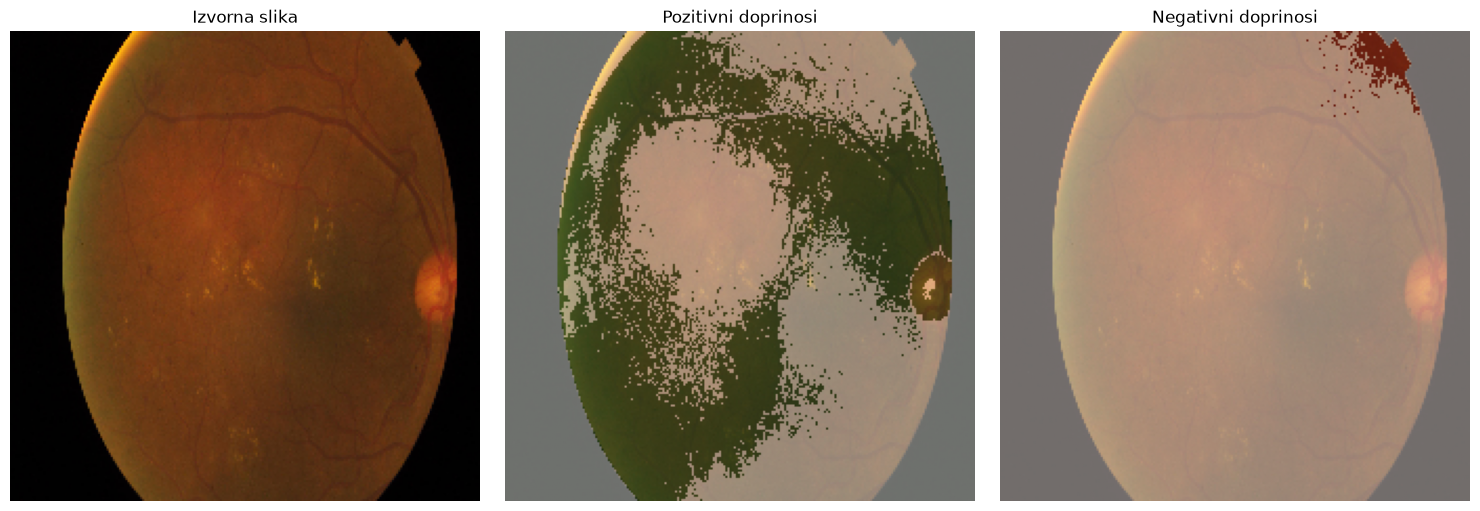

In [17]:
positive_mask = lime_mask_all == 1
negative_mask = lime_mask_all == -1

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_array.astype(np.uint8))
plt.title("Izvorna slika")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img_array.astype(np.uint8))
plt.imshow(
    positive_mask,
    alpha=0.45,
    cmap="Greens"
)
plt.title("Pozitivni doprinosi")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_array.astype(np.uint8))
plt.imshow(
    negative_mask,
    alpha=0.45,
    cmap="Reds"
)
plt.title("Negativni doprinosi")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
print("Vrijednosti u maski:", np.unique(lime_mask_all))

Vrijednosti u maski: [0 1]


In [16]:
lime_image_all, lime_mask_all = explanation.get_image_and_mask(
    label=predicted_index,
    positive_only=False,
    num_features=20,
    hide_rest=False
)

In [18]:
OUTPUT_DIR = "../Results/LIME/all_classes"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TEST_PATH = "../Dataset/"

selected_images = {
    "Mild_DR": "0024cdab0c1e.png",
    "Moderate_DR": "000c1434d8d7.png",
    "No_DR": "002c21358ce6.png",
    "Proliferate_DR": "001639a390f0.png",
    "Severe_DR": "0104b032c141.png"
}

  0%|          | 0/1000 [00:00<?, ?it/s]

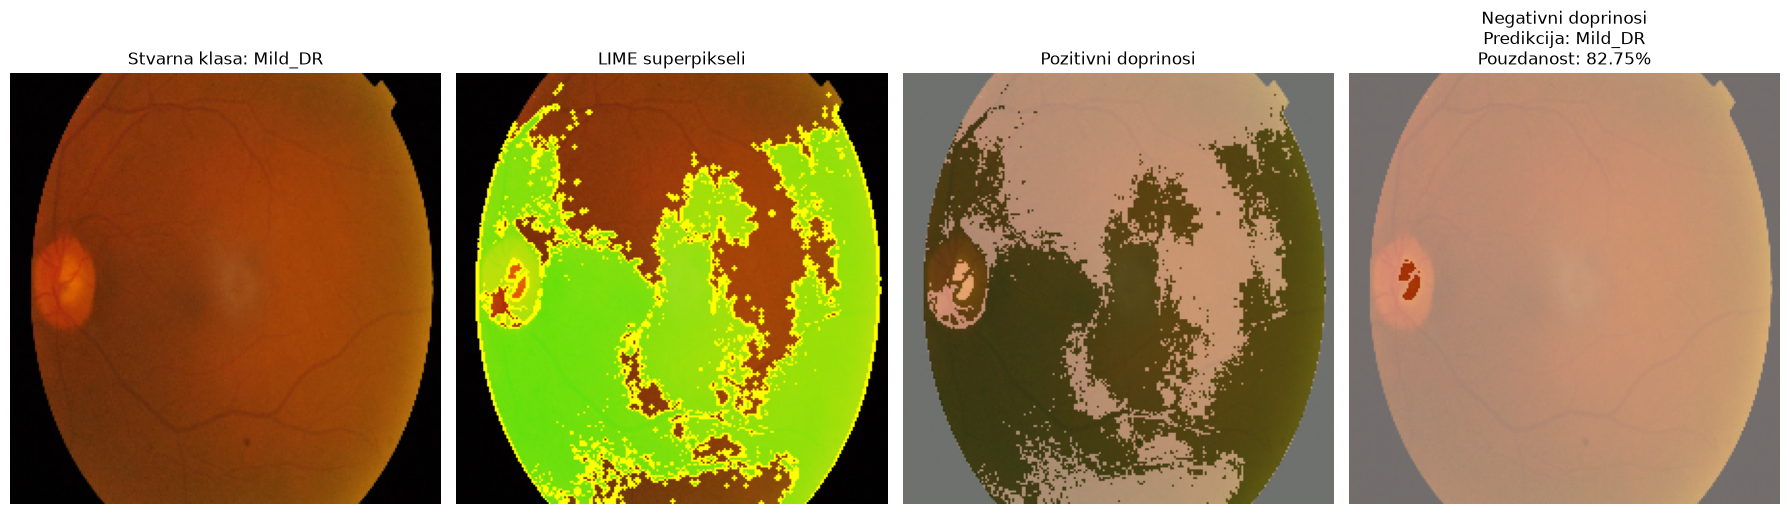

Mild_DR → Mild_DR (82.75%), maska: [-1  0  1]


  0%|          | 0/1000 [00:00<?, ?it/s]

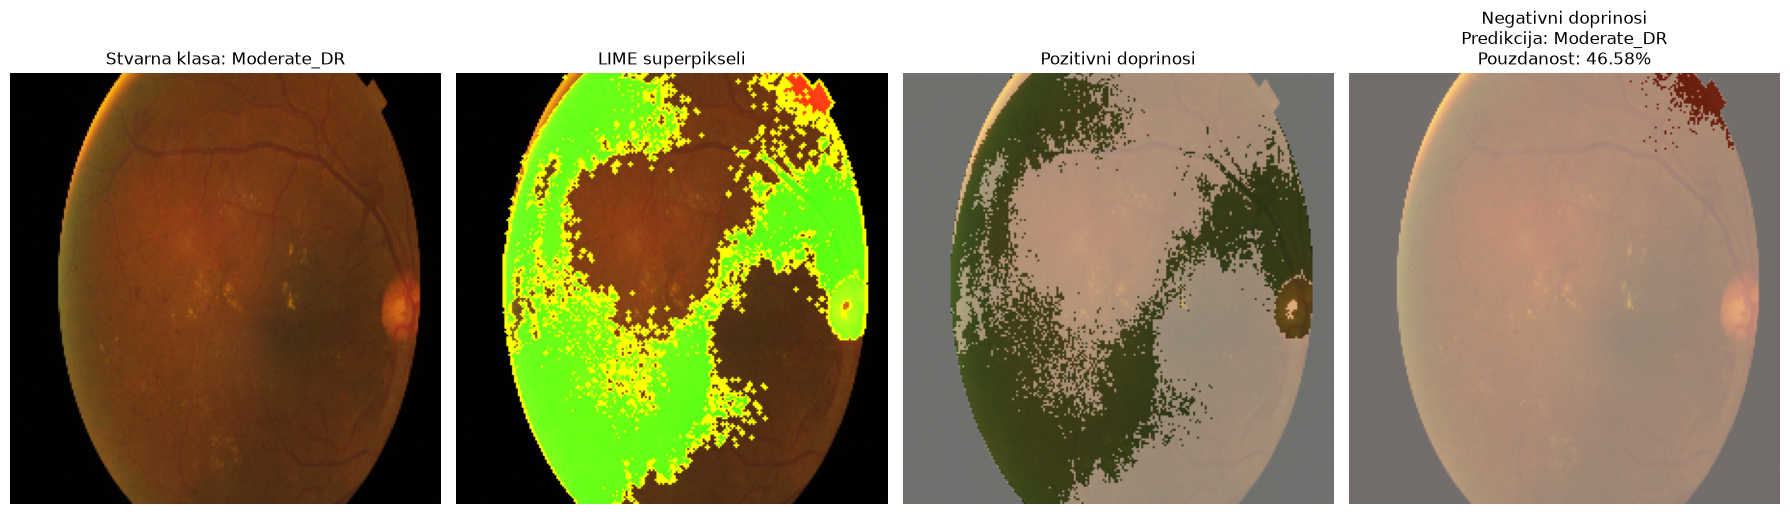

Moderate_DR → Moderate_DR (46.58%), maska: [-1  0  1]


  0%|          | 0/1000 [00:00<?, ?it/s]

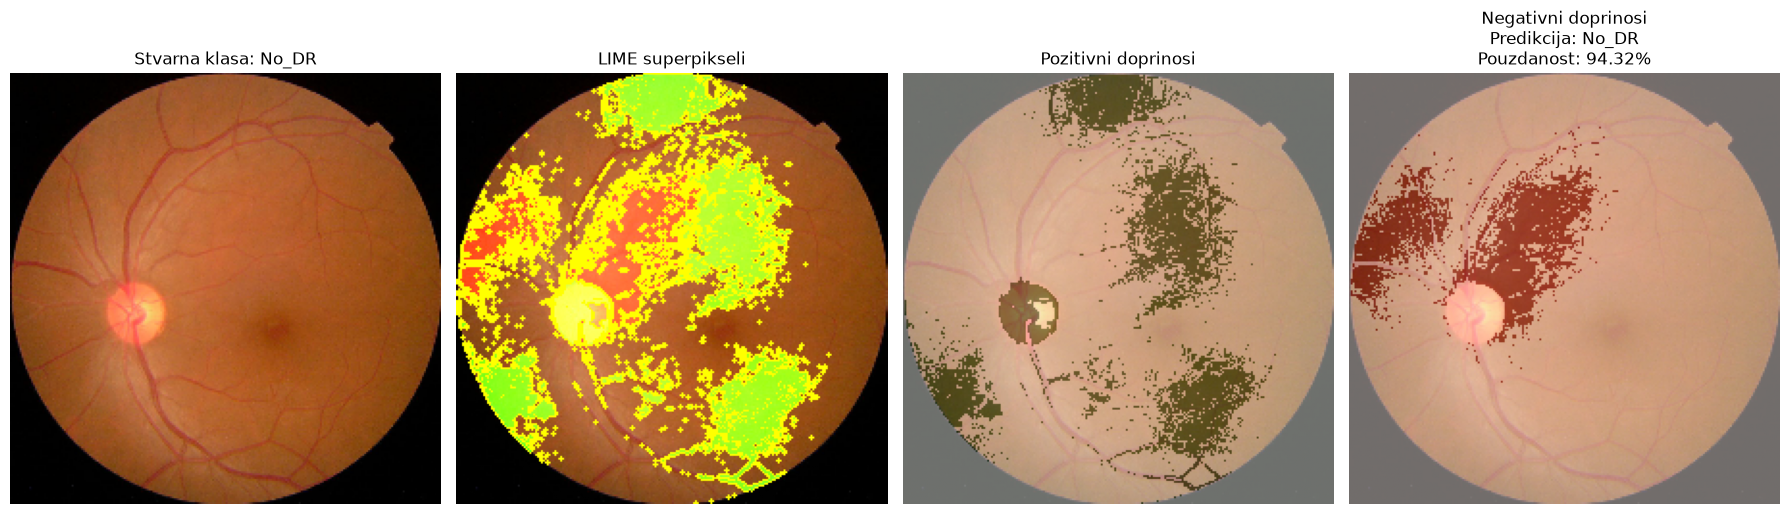

No_DR → No_DR (94.32%), maska: [-1  0  1]


  0%|          | 0/1000 [00:00<?, ?it/s]

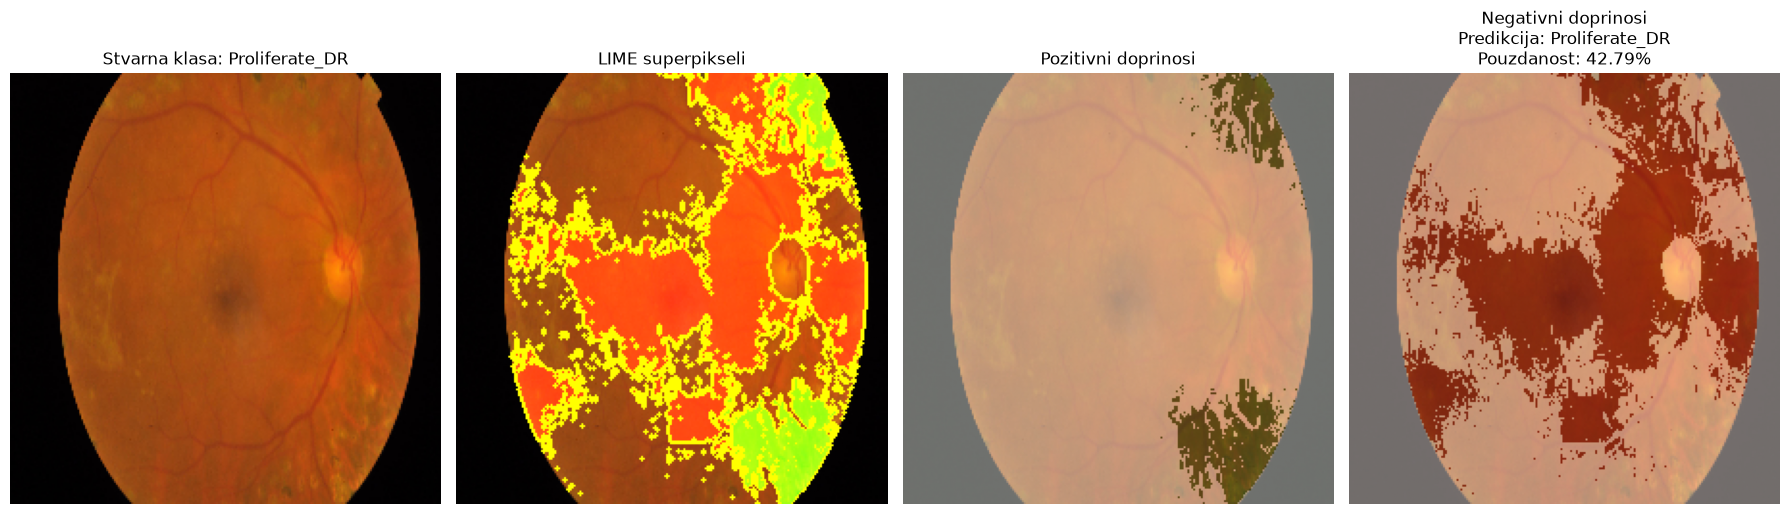

Proliferate_DR → Proliferate_DR (42.79%), maska: [-1  0  1]


  0%|          | 0/1000 [00:00<?, ?it/s]

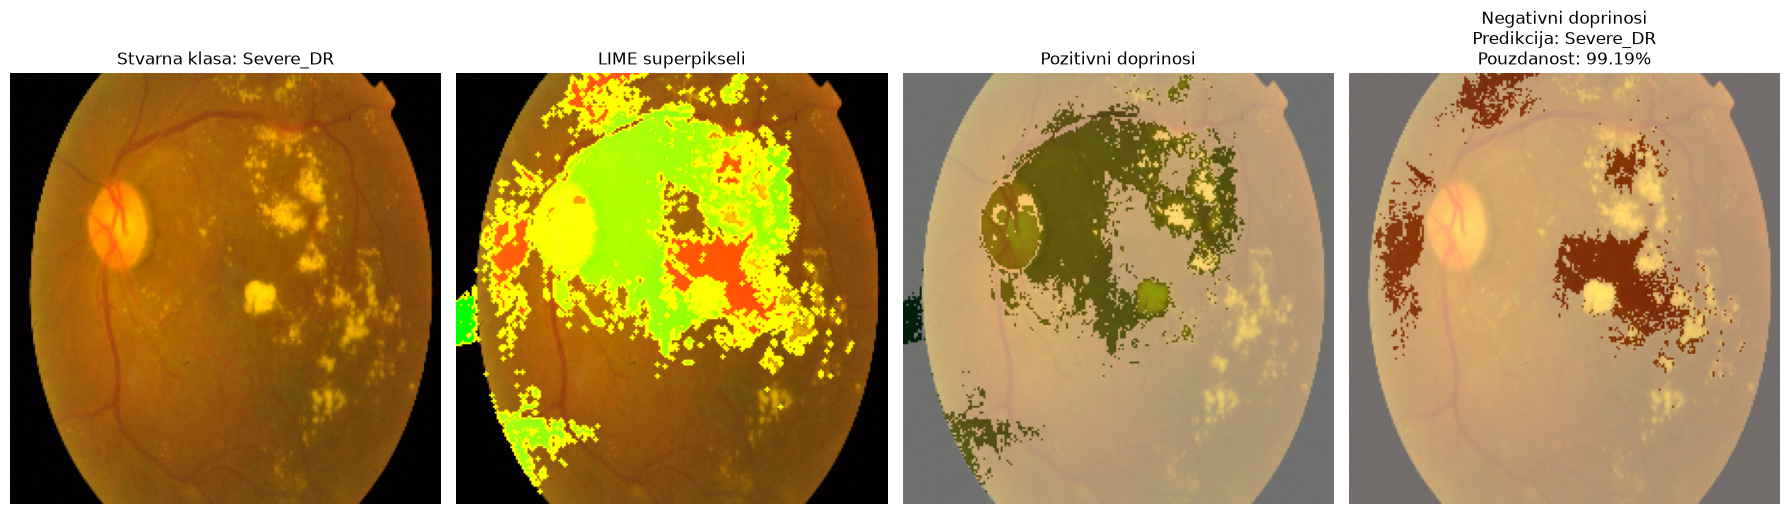

Severe_DR → Severe_DR (99.19%), maska: [-1  0  1]


In [19]:
lime_results = []

for true_class, image_name in selected_images.items():

    image_path = os.path.join(
        TEST_PATH,
        true_class,
        image_name
    )

    img = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)

    prediction = predict_images(
        np.expand_dims(img_array, axis=0)
    )

    predicted_index = int(
        np.argmax(prediction[0])
    )

    predicted_class = class_names[predicted_index]

    confidence = float(
        prediction[0][predicted_index]
    )

    explainer = lime_image.LimeImageExplainer(
        random_state=42
    )

    explanation = explainer.explain_instance(
        image=img_array.astype(np.double),
        classifier_fn=predict_images,
        top_labels=5,
        hide_color=0,
        num_samples=1000
    )

    lime_img, lime_mask = (
        explanation.get_image_and_mask(
            label=predicted_index,
            positive_only=False,
            num_features=15,
            hide_rest=False
        )
    )

    positive_mask = lime_mask == 1
    negative_mask = lime_mask == -1

    num_positive = int(
        np.sum(np.unique(lime_mask) == 1)
    )

    num_negative = int(
        np.sum(np.unique(lime_mask) == -1)
    )

    is_correct = true_class == predicted_class

    output_filename = (
        f"{true_class}_pred_{predicted_class}.png"
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        output_filename
    )

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(img_array.astype(np.uint8))
    plt.title(f"Stvarna klasa: {true_class}")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(
        mark_boundaries(
            lime_img / 255.0,
            lime_mask
        )
    )
    plt.title("LIME superpikseli")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(img_array.astype(np.uint8))
    plt.imshow(
        positive_mask,
        alpha=0.45,
        cmap="Greens"
    )
    plt.title("Pozitivni doprinosi")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(img_array.astype(np.uint8))
    plt.imshow(
        negative_mask,
        alpha=0.45,
        cmap="Reds"
    )
    plt.title(
        f"Negativni doprinosi\n"
        f"Predikcija: {predicted_class}\n"
        f"Pouzdanost: {confidence:.2%}"
    )
    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    lime_results.append({
        "stvarna_klasa": true_class,
        "predvidena_klasa": predicted_class,
        "pouzdanost": confidence,
        "tocna_predikcija": is_correct,
        "slika": image_name,
        "vrijednosti_maske": str(
            np.unique(lime_mask).tolist()
        ),
        "spremljeno_u": output_path
    })

    print(
        f"{true_class} → {predicted_class} "
        f"({confidence:.2%}), "
        f"maska: {np.unique(lime_mask)}"
    )

In [20]:
import pandas as pd

lime_results_df = pd.DataFrame(lime_results)

lime_results_df[
    [
        "stvarna_klasa",
        "predvidena_klasa",
        "pouzdanost",
        "tocna_predikcija",
        "vrijednosti_maske"
    ]
]

,stvarna_klasa,predvidena_klasa,pouzdanost,tocna_predikcija,vrijednosti_maske
0,Mild_DR,Mild_DR,0.827542,True,"[-1, 0, 1]"
1,Moderate_DR,Moderate_DR,0.465778,True,"[-1, 0, 1]"
2,No_DR,No_DR,0.943162,True,"[-1, 0, 1]"
3,Proliferate_DR,Proliferate_DR,0.427932,True,"[-1, 0, 1]"
4,Severe_DR,Severe_DR,0.991850,True,"[-1, 0, 1]"


In [21]:
results_csv_path = os.path.join(
    OUTPUT_DIR,
    "lime_results.csv"
)

lime_results_df.to_csv(
    results_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Tablica spremljena u:", results_csv_path)

Tablica spremljena u: ../Results/LIME/all_classes\lime_results.csv


In [22]:
for n_features in [5, 10, 15, 20]:
    _, mask = explanation.get_image_and_mask(
        label=predicted_index,
        positive_only=False,
        num_features=n_features,
        hide_rest=False
    )

    print(
        f"num_features={n_features}: "
        f"{np.unique(mask)}"
    )

num_features=5: [-1  0  1]
num_features=10: [-1  0  1]
num_features=15: [-1  0  1]
num_features=20: [-1  0  1]
